# Analyze a Saved Architecture Comparison Run

This notebook loads one saved run from `results/` and creates a compact, student-friendly analysis of the holdout results.

It focuses on two kinds of figures:

1. For each test function, one `2 x 2` comparison figure with:
   - `MAPE` results
   - runtime results
   - `R^2` results
   - `MAPE` vs `R^2`
2. Learning-behaviour figures based on the saved history files, using only:
   - train mean
   - validation mean
   - a confidence band (`mean +/- 1 std`)

The goal is to make the comparisons easy to read without too much clutter.


## Setup

Set the run name in the next cell. The notebook then reads the saved summary CSV and the history JSON files for that run.


In [1]:
from pathlib import Path
import json
import os
import re
import sys

mpl_config = Path("/tmp/matplotlib")
mpl_config.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_config))

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
repo_root = next(path for path in candidates if (path / "src" / "qvnn_pc").exists())
sys.path.insert(0, str(repo_root / "src"))

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from qvnn_pc.config import get_model_hyperparameters
from qvnn_pc.data import make_benchmark_regression_split
from qvnn_pc.models import CMLPQuaternionMLP, GHRQuaternionMLP, quaternion_mae_loss, scalar_regression_metrics


In [2]:
RUN_NAME = "archcmp_resume"
SUMMARY_FILE = "architecture_comparison.csv"
RUN_CONFIG_FILE = "run_config.json"
SHOW_FUNCTIONS = None  # Example: ["ackley", "rastrigin"]
SHOW_MODELS = None     # Example: ["CMLP", "GHR"]
FIG_DPI = 120


In [3]:
def _resolve_torch_dtype(dtype_name):
    if dtype_name is None:
        return torch.float32
    if isinstance(dtype_name, torch.dtype):
        return dtype_name
    key = str(dtype_name).split(".")[-1]
    if hasattr(torch, key):
        return getattr(torch, key)
    raise ValueError(f"Unsupported dtype value: {dtype_name!r}")


def _load_json_file(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def _build_model_from_artifact(artifact: dict, *, device, dtype):
    architecture = str(artifact["architecture"]).lower()
    layer_sizes = tuple(int(size) for size in artifact["layer_sizes"])
    activation = str(artifact["activation"])
    optimizer = str(artifact["optimizer"])
    lr = float(artifact["learning_rate"])

    if architecture == "cmlp":
        model = CMLPQuaternionMLP(
            layer_sizes=layer_sizes,
            activation=activation,
            optimizer=optimizer,
            lr=lr,
            device=device,
            dtype=dtype,
        )
    elif architecture == "ghr":
        model = GHRQuaternionMLP(
            layer_sizes=layer_sizes,
            activation=activation,
            optimizer=optimizer,
            lr=lr,
            device=device,
            dtype=dtype,
        )
    else:
        raise ValueError(f"Unsupported architecture in artifact: {architecture!r}")

    model.load_state_dict(artifact["state_dict"])
    return model


def _rebuild_summary_from_artifacts(run_dir: Path) -> pd.DataFrame:
    run_config_path = run_dir / RUN_CONFIG_FILE
    hyperparameters_path = run_dir / "hyperparameters.yml"
    models_dir = run_dir / "models"

    if not run_config_path.exists():
        raise FileNotFoundError(
            f"Summary file is missing and run config not found: {run_config_path}"
        )
    if not models_dir.exists():
        raise FileNotFoundError(f"Summary file is missing and model directory not found: {models_dir}")

    run_config = _load_json_file(run_config_path)
    benchmarks = list(run_config.get("benchmarks", []))
    if not benchmarks:
        raise ValueError(f"Run config does not contain any benchmarks: {run_config_path}")

    dataset_size = int(run_config["dataset_size"])
    sample_seed = int(run_config["sample_seed"])
    split_seed = int(run_config["split_seed"])
    device_value = run_config.get("device")
    device = None if device_value in (None, "None", "null") else torch.device(str(device_value))
    dtype = _resolve_torch_dtype(run_config.get("dtype"))

    rows = []
    for model_path in sorted(models_dir.glob("*.pt")):
        artifact = torch.load(model_path, map_location="cpu")
        benchmark = str(artifact["benchmark"])
        architecture = str(artifact["architecture"]).lower()
        repetition = int(artifact["repetition"])

        if benchmark not in benchmarks:
            raise ValueError(
                f"Artifact {model_path.name} refers to benchmark {benchmark!r}, which is not listed in {run_config_path}."
            )

        benchmark_idx = benchmarks.index(benchmark)
        split = make_benchmark_regression_split(
            benchmark,
            n=dataset_size,
            sample_seed=sample_seed + benchmark_idx,
            split_seed=split_seed + benchmark_idx,
            device=device,
            dtype=dtype,
        )

        model = _build_model_from_artifact(artifact, device=device, dtype=dtype)
        test_pred = model.forward(split.x_test)
        test_metrics = scalar_regression_metrics(test_pred, split.y_test)
        test_qmae = float(quaternion_mae_loss(test_pred, split.y_test).detach().cpu())

        history = {}
        history_relpath = artifact.get("history_relpath")
        history_path = None
        if history_relpath:
            candidate = run_dir / Path(str(history_relpath))
            if candidate.exists():
                history_path = candidate
        if history_path is None:
            candidate = run_dir / "history" / f"{benchmark}_{architecture}_rep{repetition:02d}.json"
            if candidate.exists():
                history_path = candidate
        if history_path is None:
            history_path_value = artifact.get("history_path")
            if history_path_value:
                candidate = Path(str(history_path_value))
                if candidate.exists():
                    history_path = candidate
                elif str(candidate).startswith("/workspace/"):
                    remapped = repo_root / candidate.relative_to("/workspace")
                    if remapped.exists():
                        history_path = remapped
        if history_path is not None:
            history = _load_json_file(history_path)

        rows.append(
            {
                "repetition": repetition,
                "algorithm": "CMLP" if architecture == "cmlp" else "GHR",
                "test_function": benchmark,
                "learning_rate": float(artifact.get("learning_rate", np.nan)),
                "optimizer": str(artifact.get("optimizer", "")),
                "activation": str(artifact.get("activation", "")),
                "batch_size": int(artifact.get("batch_size", 1)),
                "test_quaternion_mae": test_qmae,
                "test_mse": test_metrics["mse"],
                "test_mae": test_metrics["mae"],
                "test_mape": test_metrics["mape"],
                "test_r2": test_metrics["r2"],
                "epochs": int(history.get("epochs_ran", len(history.get("quaternion_mae", [])))),
                "runtime_seconds": float(history.get("runtime", np.nan)),
            }
        )

    summary_df = pd.DataFrame(rows)
    if summary_df.empty:
        raise ValueError(f"No completed model artifacts found in {models_dir}.")

    preferred_function_order = ["ackley", "griewank", "rastrigin", "schwefel"]
    function_order = [name for name in preferred_function_order if name in set(summary_df["test_function"])]
    function_order += [name for name in sorted(summary_df["test_function"].unique()) if name not in function_order]

    preferred_model_order = ["CMLP", "GHR", "Arena", "Nitta"]
    model_order = [name for name in preferred_model_order if name in set(summary_df["algorithm"])]
    model_order += [name for name in sorted(summary_df["algorithm"].unique()) if name not in model_order]

    summary_df["test_function"] = pd.Categorical(summary_df["test_function"], categories=function_order, ordered=True)
    summary_df["algorithm"] = pd.Categorical(summary_df["algorithm"], categories=model_order, ordered=True)
    return summary_df.sort_values(["test_function", "algorithm", "repetition"]).reset_index(drop=True)


In [4]:
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
repo_root = next(path for path in candidates if (path / "src" / "qvnn_pc").exists())
results_root = repo_root / "results"
available_runs = sorted(path.name for path in results_root.iterdir() if path.is_dir())
run_dir = results_root / RUN_NAME
summary_path = run_dir / SUMMARY_FILE
history_dir = run_dir / "history"

if not run_dir.exists():
    raise FileNotFoundError(f"Run directory not found: {run_dir}")
if not history_dir.exists():
    raise FileNotFoundError(f"History directory not found: {history_dir}")

print(f"Repo root: {repo_root}")
print(f"Available runs: {available_runs}")
print(f"Selected run: {run_dir}")
print(f"Summary file: {summary_path}")
print(f"History directory exists: {history_dir.exists()}")

if summary_path.exists():
    summary_df = pd.read_csv(summary_path)
    print(f"Loaded summary CSV with {len(summary_df)} rows.")
else:
    print(f"Summary file missing at {summary_path}; reconstructing completed runs from saved model artifacts.")
    summary_df = _rebuild_summary_from_artifacts(run_dir)
    print(f"Reconstructed summary with {len(summary_df)} rows from saved model artifacts.")


Repo root: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN
Available runs: ['archcmp_resume', 'pcn-h200', 'slurm_138915']
Selected run: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN/results/archcmp_resume
Summary file: /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN/results/archcmp_resume/architecture_comparison.csv
History directory exists: True
Summary file missing at /home/lukas/src/Sem4/OML/oml_fs2026/PCQVNN/results/archcmp_resume/architecture_comparison.csv; reconstructing completed runs from saved model artifacts.
Reconstructed summary with 15 rows from saved model artifacts.


In [5]:
if SHOW_FUNCTIONS is not None:
    summary_df = summary_df[summary_df["test_function"].isin(SHOW_FUNCTIONS)].copy()
if SHOW_MODELS is not None:
    summary_df = summary_df[summary_df["algorithm"].isin(SHOW_MODELS)].copy()

if summary_df.empty:
    raise ValueError("The selected filters removed all rows.")

preferred_function_order = ["ackley", "griewank", "rastrigin", "schwefel"]
function_order = [name for name in preferred_function_order if name in set(summary_df["test_function"])]
function_order += [name for name in sorted(summary_df["test_function"].unique()) if name not in function_order]

preferred_model_order = ["CMLP", "GHR", "Arena", "Nitta"]
model_order = [name for name in preferred_model_order if name in set(summary_df["algorithm"])]
model_order += [name for name in sorted(summary_df["algorithm"].unique()) if name not in model_order]

summary_df["test_function"] = pd.Categorical(summary_df["test_function"], categories=function_order, ordered=True)
summary_df["algorithm"] = pd.Categorical(summary_df["algorithm"], categories=model_order, ordered=True)
summary_df = summary_df.sort_values(["test_function", "algorithm", "repetition"]).reset_index(drop=True)

summary_df


,repetition,algorithm,test_function,learning_rate,optimizer,activation,batch_size,test_quaternion_mae,test_mse,test_mae,test_mape,test_r2,epochs,runtime_seconds
0,1,CMLP,ackley,0.004734,Adadelta,sigmoid,1,0.318208,0.174713,0.317737,0.015734,0.867534,0,NaN
1,2,CMLP,ackley,0.004734,Adadelta,sigmoid,1,0.314276,0.170395,0.313454,0.015496,0.870808,0,NaN
2,3,CMLP,ackley,0.004734,Adadelta,sigmoid,1,0.317542,0.171946,0.316789,0.015672,0.869633,0,NaN
3,4,CMLP,ackley,0.004734,Adadelta,sigmoid,1,0.313451,0.165185,0.312259,0.015439,0.874758,0,NaN
4,5,CMLP,ackley,0.004734,Adadelta,sigmoid,1,0.325138,0.189304,0.324889,0.016210,0.856472,0,NaN
5,1,GHR,ackley,0.001826,SGD,tanh,1,0.716114,1.376742,0.715839,0.037637,-0.043831,0,NaN
6,2,GHR,ackley,0.001826,SGD,tanh,1,0.714915,1.394453,0.714879,0.037653,-0.057259,0,NaN
7,3,GHR,ackley,0.001826,SGD,tanh,1,0.716946,1.369380,0.716739,0.037652,-0.038249,0,NaN
8,4,GHR,ackley,0.001826,SGD,tanh,1,0.715621,1.380671,0.715496,0.037635,-0.046810,0,NaN
9,5,GHR,ackley,0.001826,SGD,tanh,1,0.715112,1.408518,0.714982,0.037702,-0.067923,0,NaN


## Summary Tables

`MAPE` and `R^2` come from the holdout test set. Runtime is the training runtime saved for each run.

The first table is a tidy summary per function and model. The second table is a pivoted version for quicker side-by-side comparison.


In [6]:
def _format_mean_std(mean_value: float, std_value: float, digits: int = 4) -> str:
    if pd.isna(std_value):
        std_value = 0.0
    return f"{mean_value:.{digits}f} +/- {std_value:.{digits}f}"

summary_stats = (
    summary_df.groupby(["test_function", "algorithm"], observed=True)
    .agg(
        runs=("repetition", "count"),
        mape_mean=("test_mape", "mean"),
        mape_std=("test_mape", "std"),
        r2_mean=("test_r2", "mean"),
        r2_std=("test_r2", "std"),
        runtime_mean=("runtime_seconds", "mean"),
        runtime_std=("runtime_seconds", "std"),
    )
    .reset_index()
)

summary_stats["MAPE"] = summary_stats.apply(lambda row: _format_mean_std(row.mape_mean, row.mape_std), axis=1)
summary_stats["R^2"] = summary_stats.apply(lambda row: _format_mean_std(row.r2_mean, row.r2_std), axis=1)
summary_stats["Runtime (s)"] = summary_stats.apply(lambda row: _format_mean_std(row.runtime_mean, row.runtime_std, digits=2), axis=1)

tidy_table = summary_stats[["test_function", "algorithm", "runs", "MAPE", "R^2", "Runtime (s)"]]
display(tidy_table)

pivot_table = (
    summary_stats.set_index(["test_function", "algorithm"])[["MAPE", "R^2", "Runtime (s)"]]
    .unstack("algorithm")
)
display(pivot_table)


,test_function,algorithm,runs,MAPE,R^2,Runtime (s)
0,ackley,CMLP,5,0.0157 +/- 0.0003,0.8678 +/- 0.0069,nan +/- 0.00
1,ackley,GHR,5,0.0377 +/- 0.0000,-0.0508 +/- 0.0118,nan +/- 0.00
2,griewank,CMLP,5,0.0052 +/- 0.0007,0.9999 +/- 0.0001,nan +/- 0.00


MAPE                                   R^2  \
algorithm                   CMLP                GHR               CMLP   
test_function                                                            
ackley         0.0157 +/- 0.0003  0.0377 +/- 0.0000  0.8678 +/- 0.0069   
griewank       0.0052 +/- 0.0007                NaN  0.9999 +/- 0.0001   

                                    Runtime (s)                
algorithm                     GHR          CMLP           GHR  
test_function                                                  
ackley         -0.0508 +/- 0.0118  nan +/- 0.00  nan +/- 0.00  
griewank                      NaN  nan +/- 0.00           NaN

## Plot Helpers

The next helpers keep the figures visually consistent and easy to read. Every model gets the same color in every plot.


In [7]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = FIG_DPI

palette = plt.get_cmap("tab10")
model_colors = {model: palette(idx) for idx, model in enumerate(model_order)}


def _present_models(df: pd.DataFrame) -> list[str]:
    return [model for model in model_order if model in set(df["algorithm"])]


def _boxplot_with_points(ax, df: pd.DataFrame, metric_col: str, ylabel: str, title: str):
    present_models = _present_models(df)
    values = [df.loc[df["algorithm"] == model, metric_col].to_numpy() for model in present_models]
    positions = np.arange(1, len(present_models) + 1)

    box = ax.boxplot(values, positions=positions, widths=0.6, patch_artist=True, tick_labels=present_models)
    for patch, model in zip(box["boxes"], present_models):
        patch.set_facecolor(model_colors[model])
        patch.set_alpha(0.45)
    for median in box["medians"]:
        median.set_color("black")
        median.set_linewidth(1.6)

    for xpos, model, series in zip(positions, present_models, values):
        if len(series) == 0:
            continue
        offsets = np.linspace(-0.07, 0.07, num=len(series)) if len(series) > 1 else np.array([0.0])
        ax.scatter(
            np.full(len(series), xpos) + offsets,
            series,
            color=model_colors[model],
            edgecolor="black",
            linewidth=0.5,
            s=34,
            zorder=3,
        )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(ylabel)


def plot_function_comparison(function_name: str, df: pd.DataFrame):
    function_df = df[df["test_function"] == function_name].copy()
    present_models = _present_models(function_df)
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), squeeze=False)
    axes = axes.ravel()

    _boxplot_with_points(
        axes[0],
        function_df,
        metric_col="test_mape",
        ylabel="MAPE",
        title=f"{function_name.capitalize()} MAPE Results (lower is better)",
    )
    _boxplot_with_points(
        axes[1],
        function_df,
        metric_col="runtime_seconds",
        ylabel="Runtime (seconds)",
        title=f"{function_name.capitalize()} Runtime Results (lower is better)",
    )
    _boxplot_with_points(
        axes[2],
        function_df,
        metric_col="test_r2",
        ylabel="R^2",
        title=f"{function_name.capitalize()} R^2 Results (higher is better)",
    )

    for model in present_models:
        model_df = function_df[function_df["algorithm"] == model]
        axes[3].scatter(
            model_df["test_mape"],
            model_df["test_r2"],
            color=model_colors[model],
            s=60,
            alpha=0.9,
            edgecolor="black",
            linewidth=0.5,
            label=model,
        )
    axes[3].set_title(f"{function_name.capitalize()} MAPE vs R^2")
    axes[3].set_xlabel("MAPE")
    axes[3].set_ylabel("R^2")
    axes[3].legend(title="Model")

    fig.suptitle(f"Holdout Comparison for {function_name.capitalize()}", fontsize=15, y=1.02)
    fig.tight_layout()
    return fig


## Plot Type 1: Holdout Comparison per Function

Read each figure like this:

- the first three panels compare the holdout distributions across models
- the last panel shows the trade-off between `MAPE` and `R^2`
- better models are usually toward **low MAPE**, **low runtime**, and **high `R^2`**


### Ackley

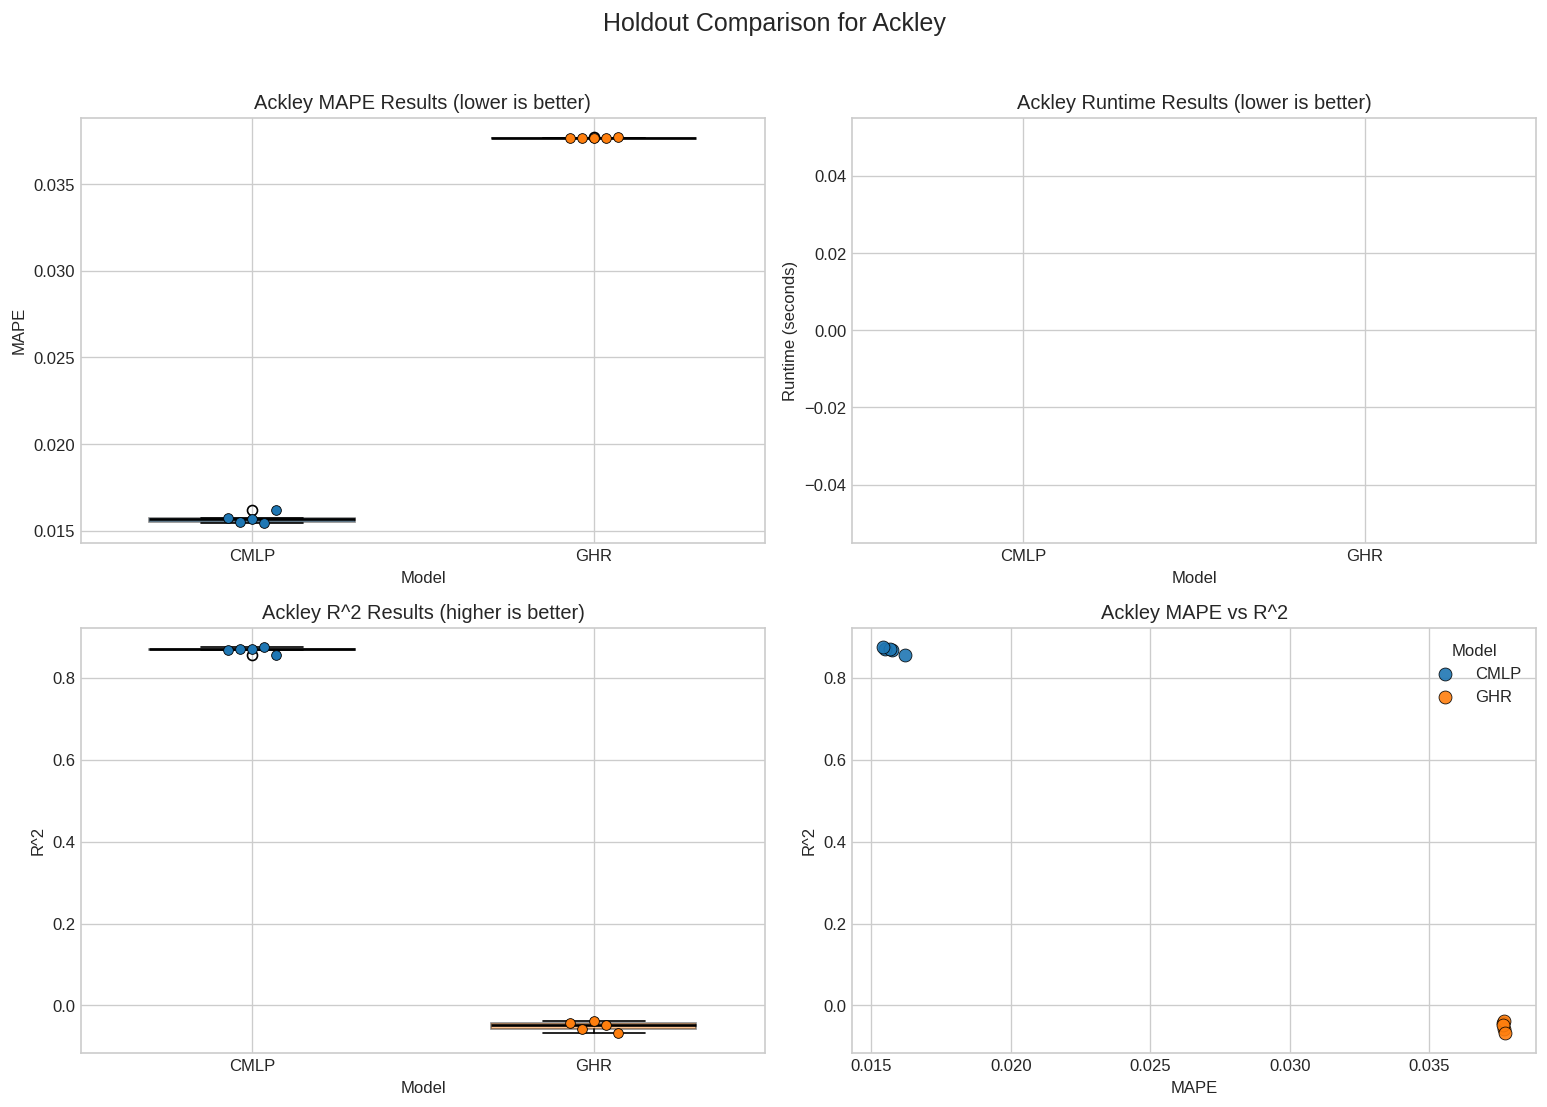

### Griewank

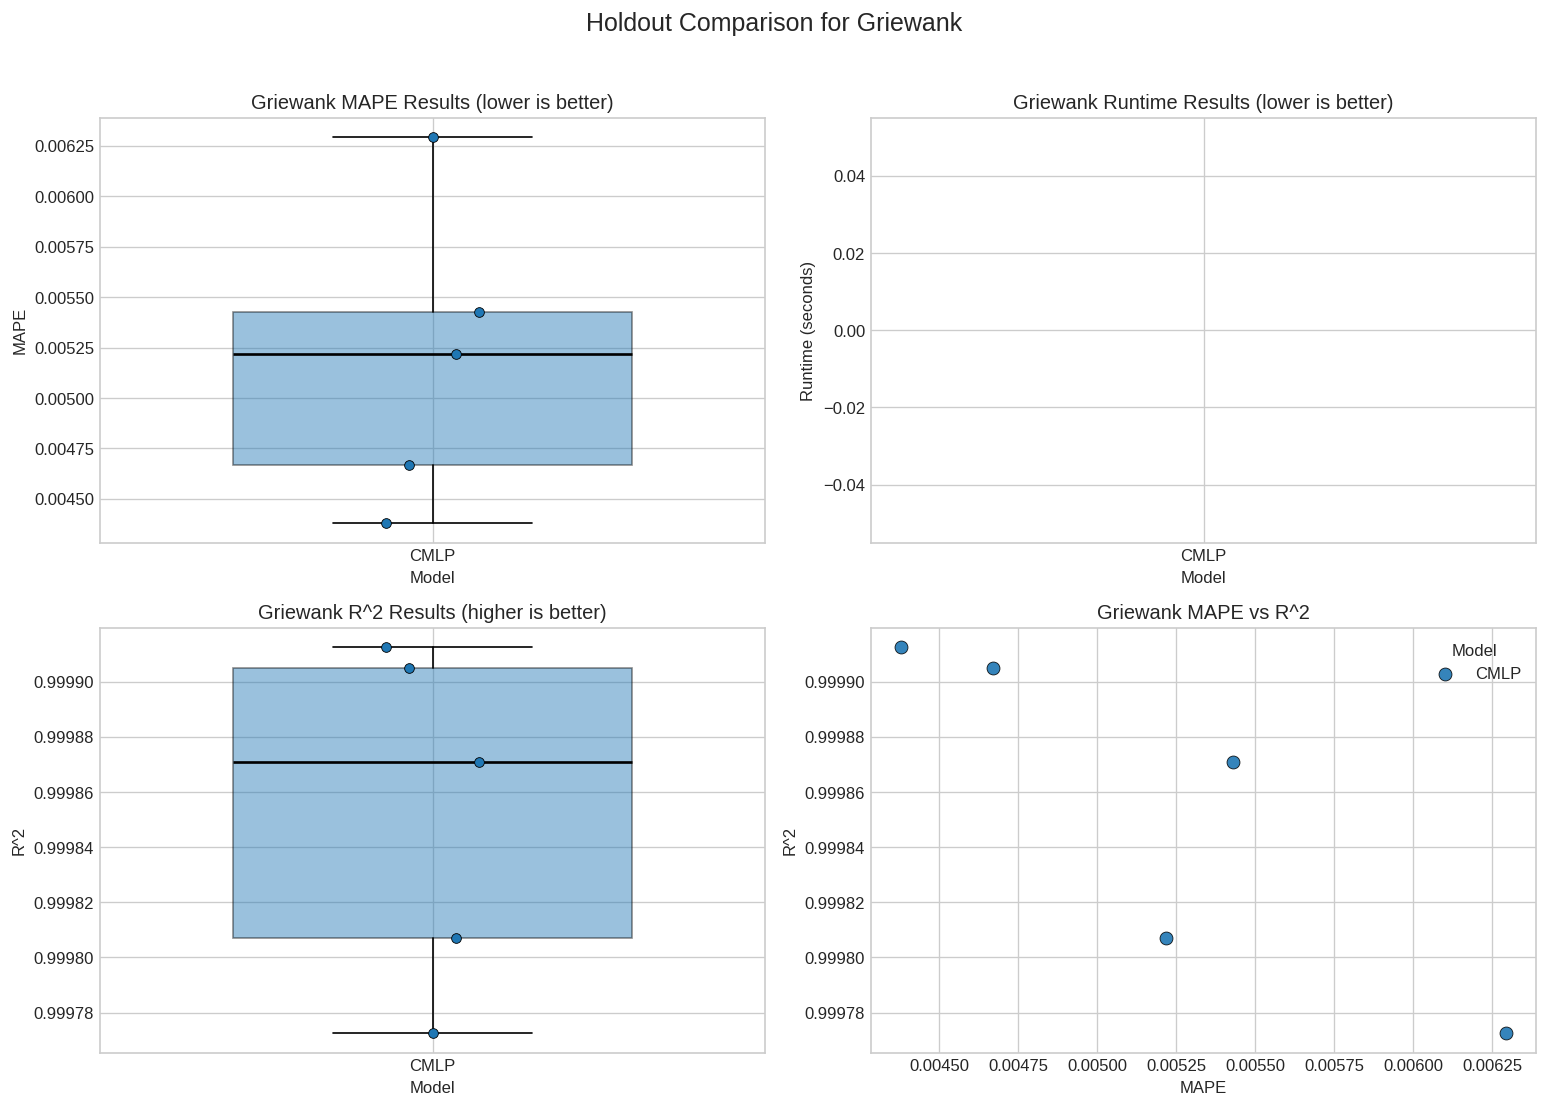

In [8]:
for function_name in function_order:
    display(Markdown(f"### {function_name.capitalize()}"))
    plot_function_comparison(function_name, summary_df)
    plt.show()


## Learning Behaviour Data

The saved history files contain per-epoch:

- training quaternion MAE
- validation quaternion MAE
- training MAPE
- training `R^2`

For clean learning plots, we will only use training and validation quaternion MAE and aggregate them across repetitions.


In [9]:
history_pattern = re.compile(r"(?P<function>.+)_(?P<algorithm>[^_]+)_rep(?P<rep>\d+)\.json")

history_rows = []
for history_path in sorted(history_dir.glob("*.json")):
    match = history_pattern.fullmatch(history_path.name)
    if match is None:
        continue
    function_name = match.group("function")
    algorithm_name = match.group("algorithm").upper()
    repetition = int(match.group("rep"))
    payload = json.loads(history_path.read_text())
    epochs_ran = int(payload.get("epochs_ran", len(payload.get("quaternion_mae", []))))

    for epoch_idx in range(epochs_ran):
        history_rows.append(
            {
                "test_function": function_name,
                "algorithm": algorithm_name,
                "repetition": repetition,
                "epoch": epoch_idx + 1,
                "train_quaternion_mae": payload["quaternion_mae"][epoch_idx],
                "validation_quaternion_mae": payload["validation_quaternion_mae"][epoch_idx],
            }
        )

history_df = pd.DataFrame(history_rows)

if not history_df.empty:
    history_df["test_function"] = pd.Categorical(history_df["test_function"], categories=function_order, ordered=True)
    history_df["algorithm"] = pd.Categorical(history_df["algorithm"], categories=model_order, ordered=True)
    history_df = history_df.sort_values(["test_function", "algorithm", "repetition", "epoch"]).reset_index(drop=True)

history_df.head()


,test_function,algorithm,repetition,epoch,train_quaternion_mae,validation_quaternion_mae
0,ackley,CMLP,1,1,0.699826,0.712712
1,ackley,CMLP,1,2,0.701978,0.714030
2,ackley,CMLP,1,3,0.590845,0.602397
3,ackley,CMLP,1,4,0.374565,0.382389
4,ackley,CMLP,1,5,0.481498,0.483601


In [10]:
def _curve_stats(subset: pd.DataFrame, value_col: str) -> pd.DataFrame:
    stats = (
        subset.groupby("epoch", observed=True)[value_col]
        .agg(["mean", "std"])
        .reset_index()
        .rename(columns={"mean": f"{value_col}_mean", "std": f"{value_col}_std"})
    )
    stats[f"{value_col}_std"] = stats[f"{value_col}_std"].fillna(0.0)
    return stats


def plot_learning_behaviour_for_function(function_name: str, history_df: pd.DataFrame):
    function_df = history_df[history_df["test_function"] == function_name].copy()
    present_models = _present_models(function_df)
    fig, axes = plt.subplots(1, len(present_models), figsize=(6.2 * len(present_models), 4.6), squeeze=False)
    axes = axes.ravel()

    train_color = "tab:blue"
    val_color = "tab:orange"

    for ax, model_name in zip(axes, present_models):
        subset = function_df[function_df["algorithm"] == model_name]
        train_stats = _curve_stats(subset, "train_quaternion_mae")
        val_stats = _curve_stats(subset, "validation_quaternion_mae")

        ax.plot(train_stats["epoch"], train_stats["train_quaternion_mae_mean"], color=train_color, linewidth=2.2, label="Train mean")
        ax.fill_between(
            train_stats["epoch"],
            train_stats["train_quaternion_mae_mean"] - train_stats["train_quaternion_mae_std"],
            train_stats["train_quaternion_mae_mean"] + train_stats["train_quaternion_mae_std"],
            color=train_color,
            alpha=0.18,
            label="Train +/- 1 std",
        )

        ax.plot(val_stats["epoch"], val_stats["validation_quaternion_mae_mean"], color=val_color, linewidth=2.2, linestyle="--", label="Validation mean")
        ax.fill_between(
            val_stats["epoch"],
            val_stats["validation_quaternion_mae_mean"] - val_stats["validation_quaternion_mae_std"],
            val_stats["validation_quaternion_mae_mean"] + val_stats["validation_quaternion_mae_std"],
            color=val_color,
            alpha=0.18,
            label="Validation +/- 1 std",
        )

        ax.set_title(f"{function_name.capitalize()} - {model_name}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Quaternion MAE")

    legend_handles = [
        Line2D([0], [0], color=train_color, linewidth=2.2, label="Train mean"),
        Line2D([0], [0], color=val_color, linewidth=2.2, linestyle="--", label="Validation mean"),
        Line2D([0], [0], color=train_color, linewidth=8, alpha=0.18, label="Train +/- 1 std"),
        Line2D([0], [0], color=val_color, linewidth=8, alpha=0.18, label="Validation +/- 1 std"),
    ]
    fig.legend(handles=legend_handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
    fig.suptitle(f"Learning Behaviour for {function_name.capitalize()}", fontsize=15, y=1.08)
    fig.tight_layout()
    return fig


## Plot Type 2: Learning Behaviour

These plots are intentionally less cluttered than before:

- no single-run lines
- solid blue line = train mean
- dashed orange line = validation mean
- shaded band = `mean +/- 1 std` across repetitions

This makes it much easier to see the general trend of each model.


### Ackley

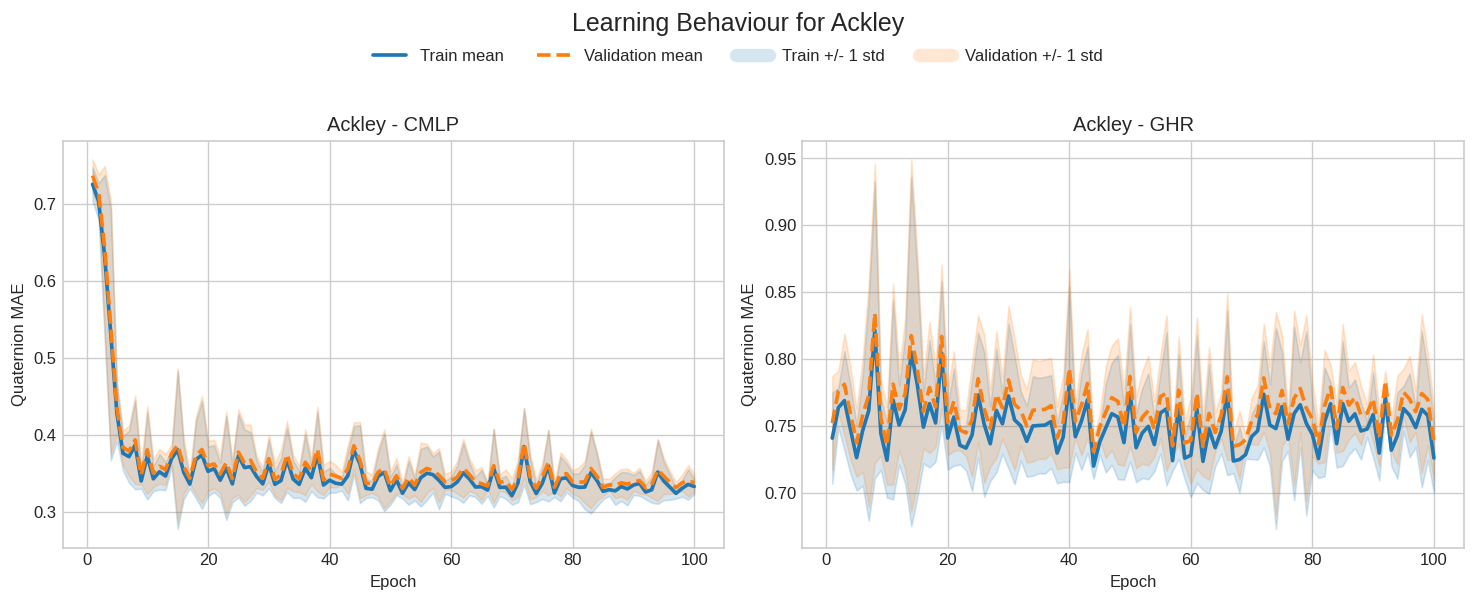

### Griewank

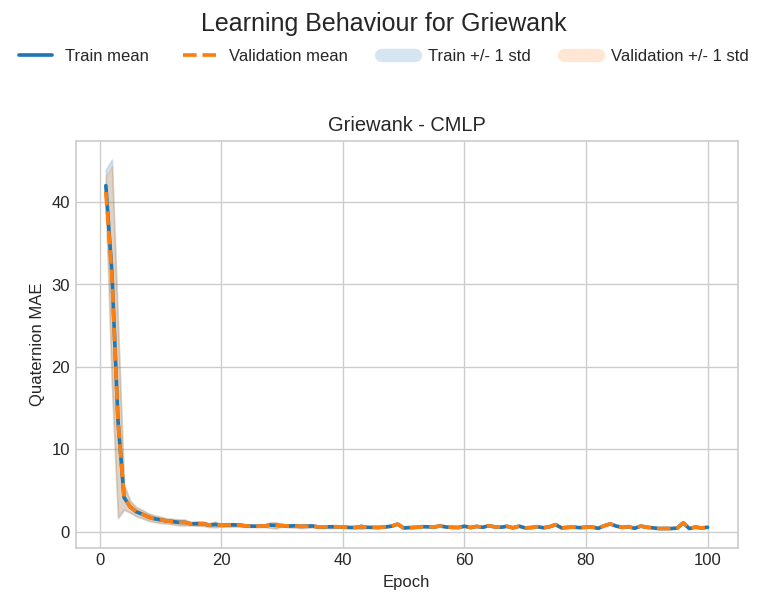

In [11]:
for function_name in function_order:
    display(Markdown(f"### {function_name.capitalize()}"))
    plot_learning_behaviour_for_function(function_name, history_df)
    plt.show()
